In [1]:

import pandas as pd

df = pd.read_csv("student_lifestyle_dataset.csv")

features = [
    "Study_Hours_Per_Day",
    "Extracurricular_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Social_Hours_Per_Day",
    "Physical_Activity_Hours_Per_Day",
]

correlations = (
    df[features + ["GPA"]]
    .corr()["GPA"]
    .drop("GPA")
    .sort_values(ascending=False)
)

print("Correlation between lifestyle features and GPA:")
print(correlations.round(3).to_string())

print("\nAverage GPA by stress level:")
print(df.groupby("Stress_Level")["GPA"].mean().round(3).to_string())


Correlation between lifestyle features and GPA:
Study_Hours_Per_Day                0.734
Sleep_Hours_Per_Day               -0.004
Extracurricular_Hours_Per_Day     -0.032
Social_Hours_Per_Day              -0.086
Physical_Activity_Hours_Per_Day   -0.341

Average GPA by stress level:
Stress_Level
High        3.262
Low         2.817
Moderate    3.025


In [2]:

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Prepare the same dataset as the original model comparison.
X = df.drop(columns=["Student_ID", "GPA"])
X = pd.get_dummies(X, columns=["Stress_Level"], dtype=int)
y = df["GPA"]

# Use the same original split for a fair comparison.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Test different Decision Tree settings on training data only.
parameters = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_leaf": [1, 3, 5, 10, 20]
}

grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid=parameters,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Evaluate the selected model on the original test set.
best_tree = grid.best_estimator_
predictions = best_tree.predict(X_test)

print("Best parameters:", grid.best_params_)
print("Tuned Decision Tree MAE:", round(mean_absolute_error(y_test, predictions), 4))
print("Tuned Decision Tree RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 4))
print("Tuned Decision Tree R2:", round(r2_score(y_test, predictions), 4))


Best parameters: {'max_depth': 3, 'min_samples_leaf': 3}
Tuned Decision Tree MAE: 0.1671
Tuned Decision Tree RMSE: 0.2085
Tuned Decision Tree R2: 0.5342


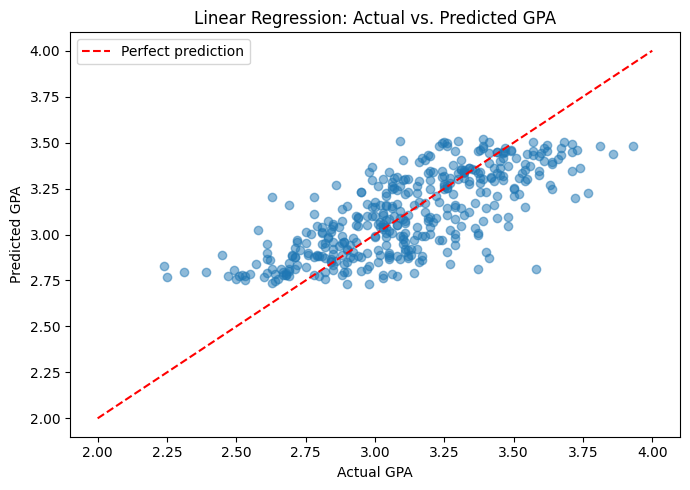

Linear Regression MAE: 0.1644
Linear Regression R2: 0.5474


In [3]:

import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Train the original Linear Regression model.
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict GPA for the original test set.
linear_predictions = linear_model.predict(X_test)

# Plot actual versus predicted GPA.
plt.figure(figsize=(7, 5))
plt.scatter(y_test, linear_predictions, alpha=0.5)
plt.plot([2, 4], [2, 4], linestyle="--", color="red",
         label="Perfect prediction")

plt.xlabel("Actual GPA")
plt.ylabel("Predicted GPA")
plt.title("Linear Regression: Actual vs. Predicted GPA")
plt.legend()
plt.tight_layout()
plt.show()

print("Linear Regression MAE:",
      round(mean_absolute_error(y_test, linear_predictions), 4))
print("Linear Regression R2:",
      round(r2_score(y_test, linear_predictions), 4))
